In [50]:
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt 
import os
from sklearn.model_selection import train_test_split
import torch
import math
from collections import Counter
import torch
import numpy as np
from sklearn.metrics import (
    confusion_matrix, 
    classification_report, 
    accuracy_score,
    precision_recall_fscore_support,
)
import matplotlib.pyplot as plt
import seaborn as sns

## Load labels

In [51]:
labels1=pd.read_csv(f'wbc-bench-2026/phase1_label.csv')
labels1.head()

,ID,labels,split,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,00185772.jpg,BL,phase1_train,NaN,NaN,NaN
1,00185756.jpg,BNE,phase1_train,NaN,NaN,NaN
2,00185821.jpg,BNE,phase1_train,NaN,NaN,NaN
3,00185845.jpg,BNE,phase1_train,NaN,NaN,NaN
4,00185854.jpg,BNE,phase1_train,NaN,NaN,NaN


In [52]:
label2=pd.read_csv("wbc-bench-2026/phase2_train.csv")
label2.head()
labels=pd.concat([labels1,label2],ignore_index=True)
labels.head()

,ID,labels,split,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,00185772.jpg,BL,phase1_train,NaN,NaN,NaN
1,00185756.jpg,BNE,phase1_train,NaN,NaN,NaN
2,00185821.jpg,BNE,phase1_train,NaN,NaN,NaN
3,00185845.jpg,BNE,phase1_train,NaN,NaN,NaN
4,00185854.jpg,BNE,phase1_train,NaN,NaN,NaN


In [53]:
labels.shape

(33185, 6)

In [54]:
labels.isna().sum()

ID                0
labels            0
split             0
Unnamed: 3    33185
Unnamed: 4    33185
Unnamed: 5    33185
dtype: int64

In [55]:
labels.drop(['Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5'], axis=1, inplace=True)

In [56]:
labels['labels'].value_counts()

labels
SNE    15048
LY      9230
MO      3195
BL      2271
EO       979
MY       513
BA       494
BNE      451
MMY      433
VLY      382
PMY      118
PC        58
PLY       13
Name: count, dtype: int64

In [57]:
labels = labels[~labels['labels'].isin(['MMY', 'BA', 'PMY', 'PLY', 'PC'])]

In [58]:
labels['labels'].value_counts()

labels
SNE    15048
LY      9230
MO      3195
BL      2271
EO       979
MY       513
BNE      451
VLY      382
Name: count, dtype: int64

#### Weights to managed unbalanced classes

In [59]:
counts = {labels['labels'].value_counts().index[i]: labels['labels'].value_counts().values[i] for i in range(len(labels['labels'].value_counts()))}

def class_balanced_weights(counts, beta=0.999):
    weights = {}
    for cls, n in counts.items():
        eff_num = (1 - beta**n) / (1 - beta)
        weights[cls] = 1.0 / eff_num

    mean_w = sum(weights.values()) / len(weights)
    return {cls: w/mean_w for cls, w in weights.items()}

weights = class_balanced_weights(counts, beta=0.999)
label_to_index = {label:i for i,label in enumerate(counts.keys())}
weight_tensor = torch.zeros(len(counts))

for label, w in weights.items():
    weight_tensor[label_to_index[label]] = w

criterion = torch.nn.CrossEntropyLoss(weight=weight_tensor)


### Load images

#### Split to train/test

In [73]:
dir='wbc-bench-2026'
train_images_path=[file for file in os.listdir(os.path.join(dir,'phase1')) if file.endswith('.jpg')]
labels

,ID,labels,split
0,00185772.jpg,BL,phase1_train
1,00185756.jpg,BNE,phase1_train
2,00185821.jpg,BNE,phase1_train
3,00185845.jpg,BNE,phase1_train
4,00185854.jpg,BNE,phase1_train
...,...,...,...
33180,01441658.jpg,SNE,phase2_train
33181,01441659.jpg,SNE,phase2_train
33182,01441660.jpg,SNE,phase2_train
33183,01441661.jpg,SNE,phase2_train


In [74]:

train_images_path2=[file for file in os.listdir('wbc-bench-2026/phase2/train') if file.endswith('.jpg')]


In [75]:
# image_df

In [76]:
image_df = pd.DataFrame({'image': train_images_path2 + train_images_path})
merged_df =pd.merge(image_df,labels,left_on='image',right_on='ID') 

In [78]:
merged_df.tail()

,image,ID,labels,split
32064,01128094.jpg,01128094.jpg,LY,phase1_train
32065,00265563.jpg,00265563.jpg,MO,phase1_train
32066,01330677.jpg,01330677.jpg,SNE,phase1_train
32067,01048012.jpg,01048012.jpg,LY,phase1_train
32068,00951772.jpg,00951772.jpg,SNE,phase1_train


In [96]:
# Fix image path construction for both phase1 and phase2/train
def get_image_path(x):
    if x in train_images_path2:
        return os.path.join('wbc-bench-2026/phase2/train', x)
    else:
        return os.path.join('wbc-bench-2026/phase1', x)
X = merged_df['image'].apply(get_image_path).values
y = merged_df['labels'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f'Train size: {len(X_train)}, Test size: {len(X_test)}')

Train size: 25655, Test size: 6414


#### Create dataloaders and transform

In [97]:
from torchvision.transforms import v2
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch

# Define transforms
transforms_v2 = v2.Compose([
    v2.ToImage(),  
    v2.RandomResizedCrop(size=(224, 224), antialias=True), 
    v2.ToDtype(torch.float32, scale=True), 
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    
])

class WBCCSVImageDataset(Dataset):
    def __init__(self, image_paths, labels, label_to_index, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.label_to_index = label_to_index
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        label = self.label_to_index[self.labels[idx]]
        return image, label



In [98]:
valid_classes = set(label_to_index.keys())
X_train_filtered = [x for x, y in zip(X_train, y_train) if y in valid_classes]
y_train_filtered = [y for y in y_train if y in valid_classes]
X_test_filtered = [x for x, y in zip(X_test, y_test) if y in valid_classes]
y_test_filtered = [y for y in y_test if y in valid_classes]

train_dataset = WBCCSVImageDataset(X_train_filtered, y_train_filtered, label_to_index, transform=transforms_v2)
test_dataset = WBCCSVImageDataset(X_test_filtered, y_test_filtered, label_to_index, transform=transforms_v2)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, num_workers=0)


In [99]:
len(valid_classes)


8

## Building model

In [100]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops import RoIPool

class ROL_CNN(nn.Module):
    def __init__(self, input_size=(224, 224), num_classes=10, roi_output_size=(7, 7)):
        """
        Custom CNN with:
        - 2 convolutional layers
        - RoI Pooling
        - Fully connected classifier
        """
        super(ROL_CNN, self).__init__()
        self.num_classes = num_classes
        self.roi_output_size = roi_output_size

        # 2 Conv layers
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=0)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(3, 3)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=0)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(3, 3) 

        # RoI Pooling layer
        self.roi_pool = RoIPool(output_size=self.roi_output_size, spatial_scale=1.0)

        # Classifier head
        flattened_size = 64 * self.roi_output_size[0] * self.roi_output_size[1]
        self.fc1 = nn.Linear(flattened_size, 128)
        self.fc2 = nn.Linear(128, self.num_classes)

    def forward(self, x):
        # x shape: [B, 3, H, W]
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool1(x)
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool2(x)  # [B, 64, H/2, W/2]

        batch_size = x.size(0)
        rois = torch.zeros(batch_size, 5, device=x.device)
        rois[:,0] = torch.arange(batch_size)  # batch index
        rois[:,1] = 0                        # x1
        rois[:,2] = 0                        # y1
        rois[:,3] = x.size(3)-1              # x2 (width-1)
        rois[:,4] = x.size(2)-1              # y2 (height-1)

        x = self.roi_pool(x, rois)           # [B, 64, roi_h, roi_w]
        x = x.view(batch_size, -1)           # flatten
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

num_classes = len(valid_classes)
device = torch.device('mps') 

model = ROL_CNN(input_size=(224,224), num_classes=num_classes).to(device)
print(model)


ROL_CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=3, stride=3, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool2d(kernel_size=3, stride=3, padding=0, dilation=1, ceil_mode=False)
  (roi_pool): RoIPool(output_size=(7, 7), spatial_scale=1.0)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=8, bias=True)
)


In [101]:
model.num_classes

8

In [102]:
import torch
import torch.nn as nn
import torch.optim as optim

def train_model(model, train_loader, val_loader, num_epochs=10, lr=0.001, device='mps', criterion=None, checkpoint_dir='checkpointsv2'):
    """
    Train the ROL_CNN model and print accuracy each epoch.
    Saves model checkpoints after each epoch.
    """
    import os
    os.makedirs(checkpoint_dir, exist_ok=True)
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    for epoch in range(1, num_epochs+1):
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        train_loss = running_loss / total_train
        train_acc = correct_train / total_train

        # Validation
        model.eval()
        correct_val = 0
        total_val = 0
        val_loss_total = 0.0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss_total += loss.item() * images.size(0)

                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        val_loss = val_loss_total / total_val
        val_acc = correct_val / total_val

        print(f"Epoch [{epoch}/{num_epochs}] "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        # Save checkpoint
        checkpoint_path = os.path.join(checkpoint_dir, f'epoch_{epoch}.pt')
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_loss': train_loss,
            'val_loss': val_loss,
            'train_acc': train_acc,
            'val_acc': val_acc
        }, checkpoint_path)
        print(f"Checkpoint saved: {checkpoint_path}")


In [ ]:
num_classes = len(label_to_index)
model = ROL_CNN(input_size=(224,224), num_classes=num_classes)
weight_tensor = weight_tensor.to(device)
criterion = torch.nn.CrossEntropyLoss(weight=weight_tensor)
train_model(
    model,
    train_loader=train_loader,
    val_loader=test_loader,
    num_epochs=20,
    lr=0.0001,
    device=device,
    criterion=criterion
)


In [ ]:
def evaluate_model(model, test_loader, device='mps', label_to_index=None):
    """
    Evaluate the model and return comprehensive metrics including confusion matrix.
    
    Args:
        model: Trained PyTorch model
        test_loader: DataLoader for test set
        device: Device to run evaluation on
        label_to_index: Dictionary mapping class names to indices
        
    Returns:
        dict: Dictionary containing all metrics
    """
    model.eval()
    model.to(device)
    
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs, 1)
            
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)
    
    # Calculate metrics
    accuracy = accuracy_score(all_labels, all_preds)
    precision, recall, f1, support = precision_recall_fscore_support(
        all_labels, all_preds, average='weighted', zero_division=0
    )
    
    # Per-class metrics
    precision_per_class, recall_per_class, f1_per_class, support_per_class = \
        precision_recall_fscore_support(all_labels, all_preds, average=None, zero_division=0)
    

    
    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    
    # Get class names
    if label_to_index:
        index_to_label = {v: k for k, v in label_to_index.items()}
        class_names = [index_to_label[i] for i in range(len(label_to_index))]
    else:
        class_names = [f"Class {i}" for i in range(cm.shape[0])]
    
    # Print results
    print("="*80)
    print("CLASSIFICATION METRICS")
    print("="*80)
    print(f"\nOverall Accuracy: {accuracy:.4f}")
    print(f"Weighted Precision: {precision:.4f}")
    print(f"Weighted Recall: {recall:.4f}")
    print(f"Weighted F1-Score: {f1:.4f}")

    
    print("\n" + "="*80)
    print("PER-CLASS METRICS")
    print("="*80)
    print(f"{'Class':<20} {'Precision':<12} {'Recall':<12} {'F1-Score':<12} {'Support':<10}")
    print("-"*80)
    for i, class_name in enumerate(class_names):
        print(f"{class_name:<20} {precision_per_class[i]:<12.4f} "
              f"{recall_per_class[i]:<12.4f} {f1_per_class[i]:<12.4f} "
              f"{support_per_class[i]:<10}")
    
    print("\n" + "="*80)
    print("DETAILED CLASSIFICATION REPORT")
    print("="*80)
    print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))
    
    # Return metrics dictionary
    metrics = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix': cm,
        'predictions': all_preds,
        'labels': all_labels,
        'probabilities': all_probs,
        'class_names': class_names,
        'per_class_metrics': {
            'precision': precision_per_class,
            'recall': recall_per_class,
            'f1': f1_per_class,
            'support': support_per_class
        }
    }
    
    return metrics


Resolved 47 packages in 495ms                                        
Installed 1 package in 7ms                                       
 + seaborn==0.13.2


In [ ]:
def plot_confusion_matrix(cm, class_names, normalize=False, figsize=(12, 10), 
                          save_path=None):
    """
    Plot confusion matrix with nice formatting.
    
    Args:
        cm: Confusion matrix array
        class_names: List of class names
        normalize: Whether to normalize the confusion matrix
        figsize: Figure size tuple
        save_path: Path to save the figure (optional)
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        fmt = '.2f'
        title = 'Normalized Confusion Matrix'
    else:
        fmt = 'd'
        title = 'Confusion Matrix'
    
    plt.figure(figsize=figsize)
    sns.heatmap(cm, annot=True, fmt=fmt, cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Count' if not normalize else 'Proportion'})
    plt.title(title, fontsize=16, pad=20)
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Confusion matrix saved to: {save_path}")
    
    plt.show()


CLASSIFICATION METRICS

Overall Accuracy: 0.8079
Weighted Precision: 0.7997
Weighted Recall: 0.8079
Weighted F1-Score: 0.8007
Cohen's Kappa: 0.7068

PER-CLASS METRICS
Class                Precision    Recall       F1-Score     Support   
--------------------------------------------------------------------------------
SNE                  0.9243       0.9515       0.9377       783       
LY                   0.8078       0.8785       0.8417       469       
MO                   0.7071       0.4730       0.5668       148       
BL                   0.5729       0.4825       0.5238       114       
EO                   0.3421       0.3611       0.3514       36        
BNE                  0.0667       0.0909       0.0769       22        
MY                   0.2000       0.3182       0.2456       22        
VLY                  0.0000       0.0000       0.0000       20        

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

         SNE       0.92   

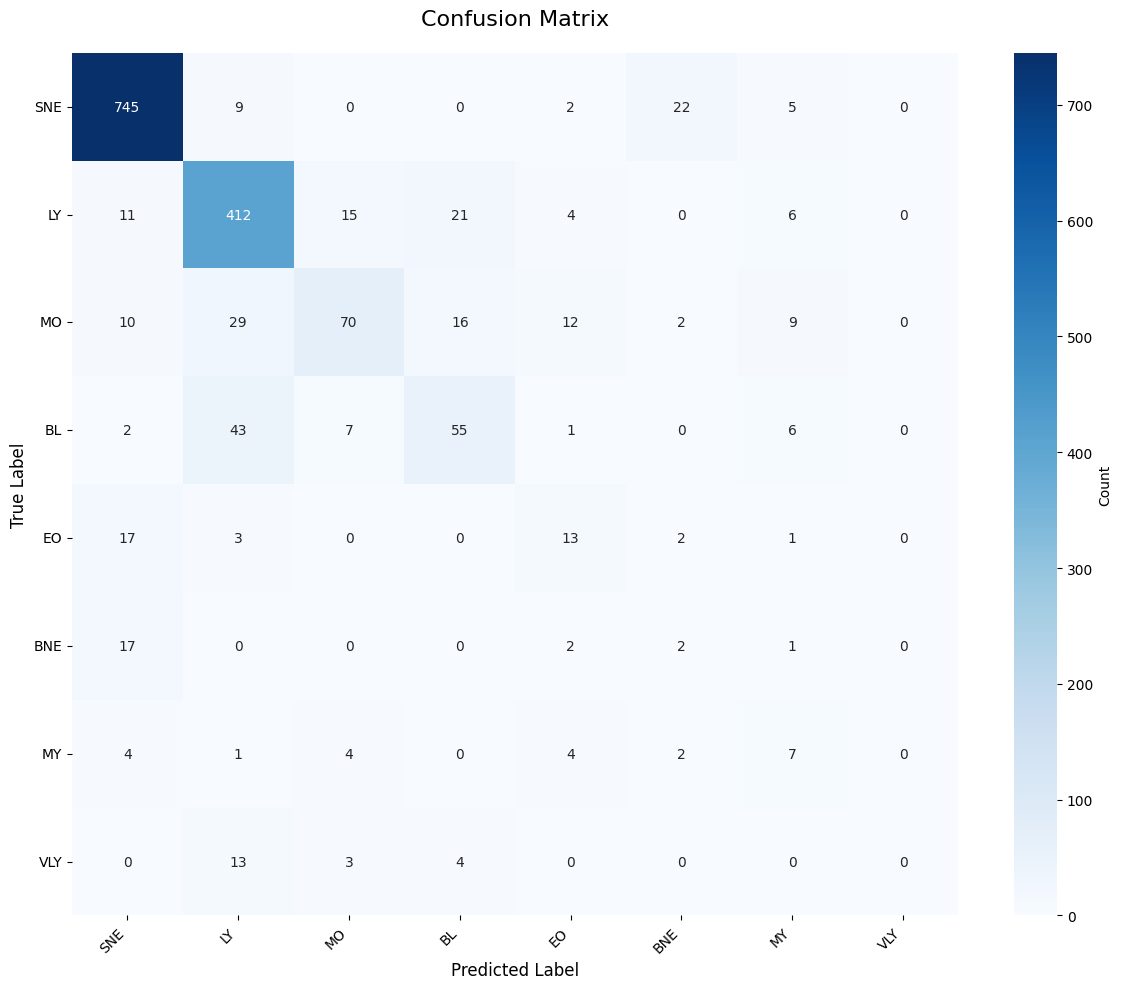

Confusion matrix saved to: confusion_matrix_normalized.png


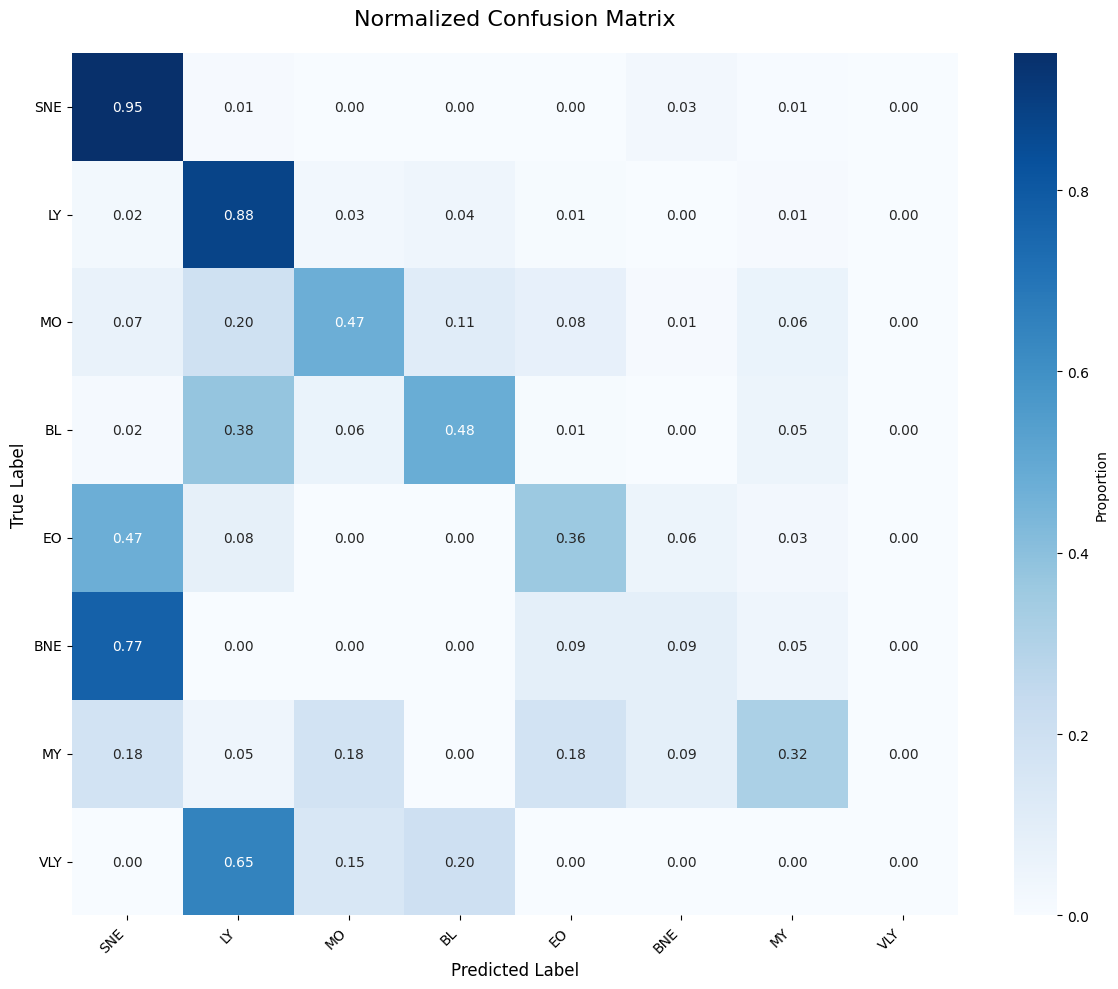

In [86]:
# After training your model, evaluate it:
metrics = evaluate_model(
        model=model,
        test_loader=test_loader,
        device=device,
        label_to_index=label_to_index
    )
    
# Plot confusion matrix (both normalized and unnormalized)
plot_confusion_matrix(
        metrics['confusion_matrix'], 
        metrics['class_names'],
        normalize=False,
        save_path='confusion_matrix.png'
    )
    
plot_confusion_matrix(
        metrics['confusion_matrix'], 
        metrics['class_names'],
        normalize=True,
        save_path='confusion_matrix_normalized.png'
    )
    


## evualuate on phase 2

In [78]:
import pandas as pd
test_labels=pd.read_csv(f'wbc-bench-2026/phase2_eval.csv')
test_labels
test_labels = test_labels[~test_labels['labels'].isin(['MMY', 'BA', 'PMY', 'PLY', 'PC'])]

In [79]:
image_df

,image
0,01442909.jpg
1,01445900.jpg
2,01445914.jpg
3,01442935.jpg
4,01445082.jpg
...,...
5345,01446592.jpg
5346,01444385.jpg
5347,01442904.jpg
5348,01445919.jpg


In [80]:

image_files = [file for file in os.listdir('wbc-bench-2026/phase2/eval') if file.endswith('.jpg')]
image_df = pd.DataFrame({'image': image_files})
merged_df =pd.merge(image_df,test_labels,left_on='image',right_on='ID', how='inner')
merged_df.shape

(5176, 4)

In [81]:
eval_dataset = WBCCSVImageDataset(
    merged_df['image'].apply(lambda x: os.path.join('wbc-bench-2026/phase2/eval', x)).values,
    merged_df['labels'].values,
    label_to_index,
    transform=transforms_v2
)
eval_loader = DataLoader(eval_dataset, batch_size=16, shuffle=False, num_workers=0)

In [82]:
merged_df

,image,ID,labels,split
0,01442909.jpg,01442909.jpg,BL,phase2_eval
1,01445900.jpg,01445900.jpg,BL,phase2_eval
2,01445914.jpg,01445914.jpg,LY,phase2_eval
3,01442935.jpg,01442935.jpg,LY,phase2_eval
4,01445082.jpg,01445082.jpg,SNE,phase2_eval
...,...,...,...,...
5171,01446592.jpg,01446592.jpg,MO,phase2_eval
5172,01444385.jpg,01444385.jpg,SNE,phase2_eval
5173,01442904.jpg,01442904.jpg,BL,phase2_eval
5174,01445919.jpg,01445919.jpg,LY,phase2_eval


CLASSIFICATION METRICS

Overall Accuracy: 0.6364
Weighted Precision: 0.7556
Weighted Recall: 0.6364
Weighted F1-Score: 0.6813
Cohen's Kappa: 0.5041

PER-CLASS METRICS
Class                Precision    Recall       F1-Score     Support   
--------------------------------------------------------------------------------
SNE                  0.9165       0.7663       0.8347       2306      
LY                   0.7420       0.7104       0.7259       1571      
MO                   0.6857       0.3605       0.4726       466       
BL                   0.4899       0.3544       0.4113       412       
EO                   0.4062       0.3077       0.3502       169       
BNE                  0.0459       0.1408       0.0692       71        
MY                   0.0399       0.4533       0.0734       75        
VLY                  0.3333       0.0094       0.0183       106       

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

         SNE       0.92   

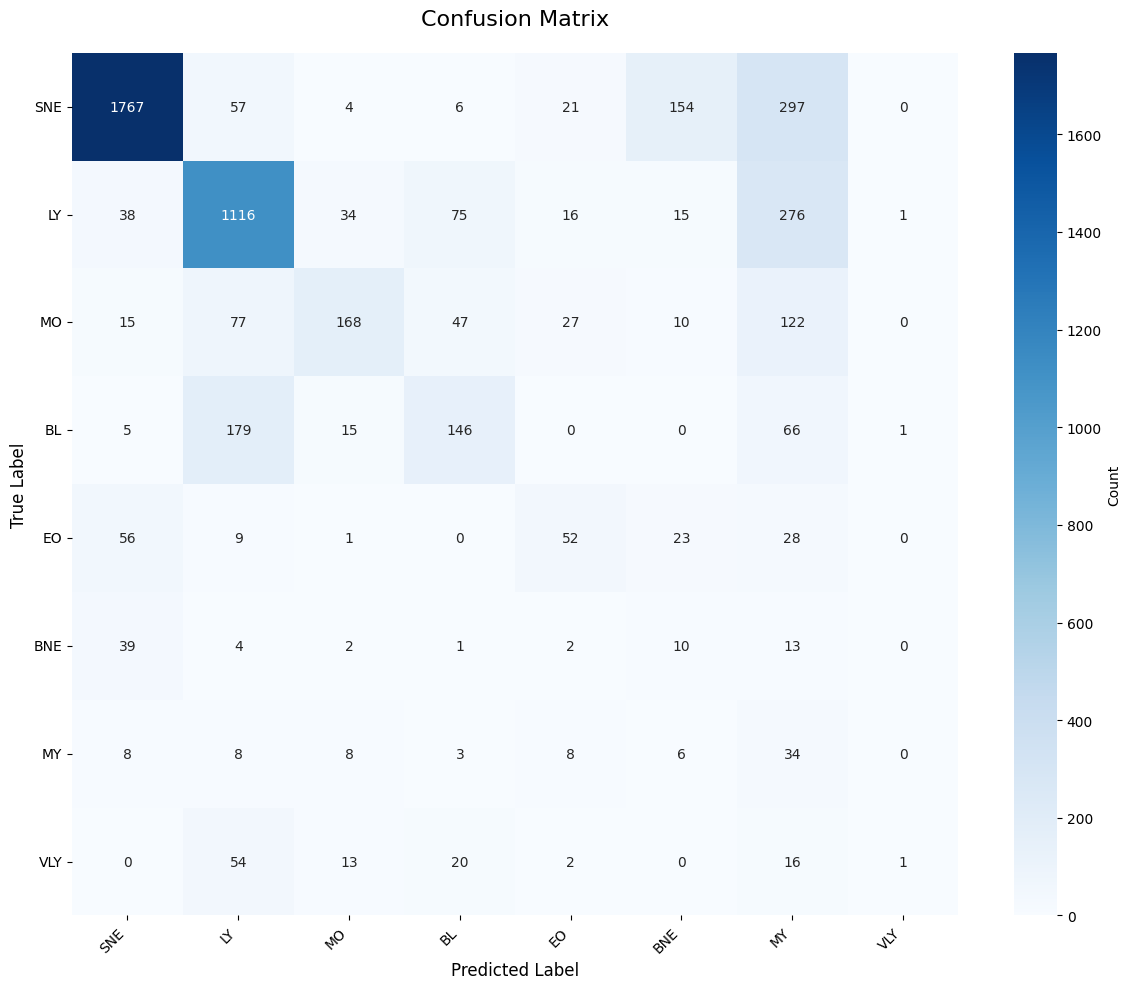

Confusion matrix saved to: confusion_matrix_normalized.png


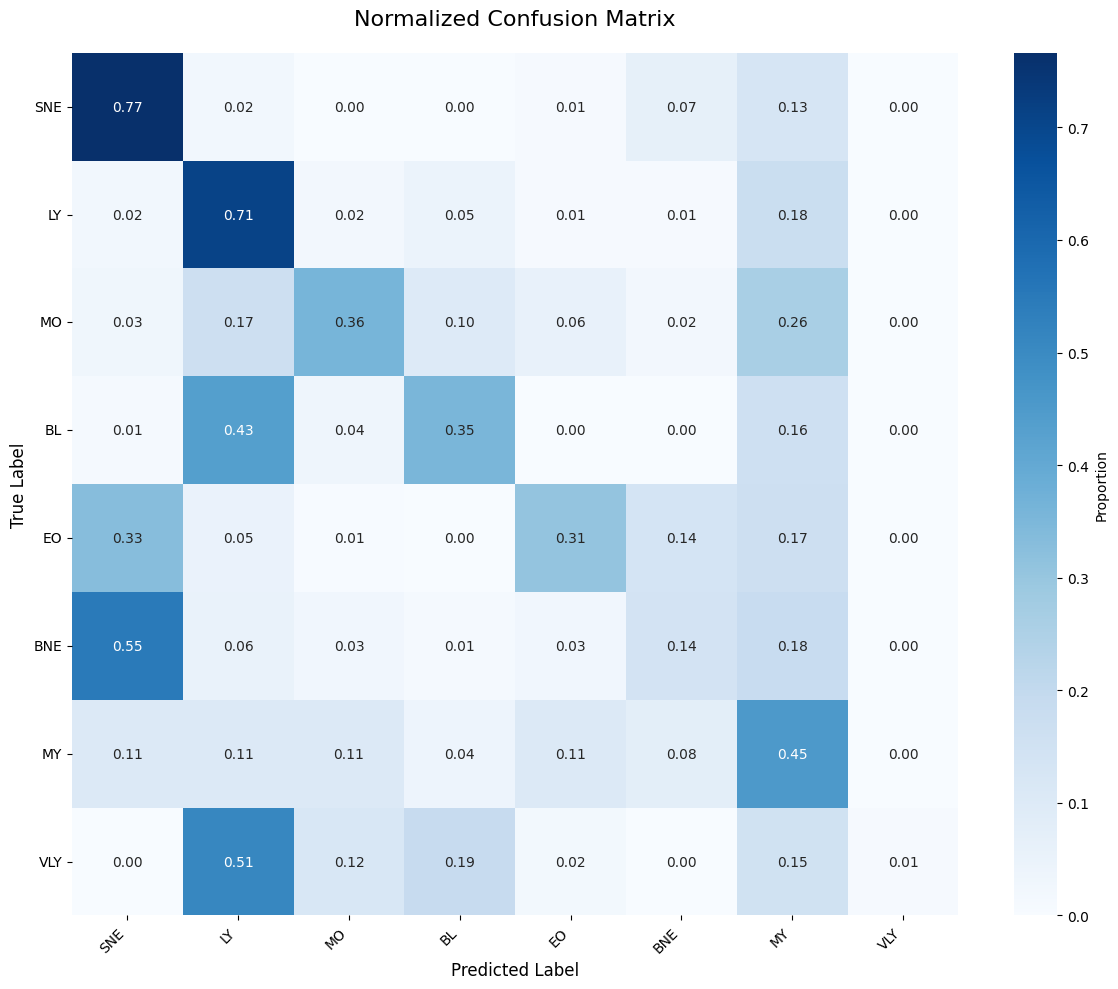

In [87]:

metrics = evaluate_model(
        model=model,
        test_loader=eval_loader,
        device=device,
        label_to_index=label_to_index
    )
    

plot_confusion_matrix(
        metrics['confusion_matrix'], 
        metrics['class_names'],
        normalize=False,
        save_path='confusion_matrix.png'
    )
    
plot_confusion_matrix(
        metrics['confusion_matrix'], 
        metrics['class_names'],
        normalize=True,
        save_path='confusion_matrix_normalized.png'
    )
    